# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot 2m temperature anomalies over all time by pattern

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
from minisom import MiniSom, asymptotic_decay
import xarray as xr
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import seaborn as sns
import pickle
import dask

In [2]:
# set path where the som finalist files are
dir_base = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/'

## Load training data to interpret SOMs

In [3]:
# set input directory
dir_in = dir_base + 'som_training/'

In [4]:
def normalize_data(data):
    """
    Function for normalizing data prior to training using z-score
    """
    return (data - np.nanmean(data)) / np.nanstd(data)

In [5]:
# open file saved in earlier notebook (soms_antarctica-gettingdata.ipynb)
subset = xr.open_dataset(dir_in+'mesaclip_training_data_alaska_psl_autumn_decadal.nc')

# assign to numpy array object
subsetarray = subset['train_data'].values

# set data
data = normalize_data(subsetarray)

# set data input length
input_length = subsetarray.shape[1]    # using preprocessed data array; Number of the elements of the vectors in input.

## Set the parameter combinations for SOM finalists

In [6]:
# set paired values for possible winning maps based on Sammon maps evaluation
som_grid_rows    = [3, 4]    # (y-axis)
som_grid_cols    = [3, 4]    # (x-axis)
ranks            = [3, 45]
sigs             = [1.0, 1.0]
lrs              = [0.01, 0.005]
nitrs            = [250000, 50000]

## MANUAL CHANGING REQUIRED HERE ##
# select which set to plot
n = 0

In [7]:
# select info for input file (set above)
som_row = som_grid_rows[n]
som_col = som_grid_cols[n]
rank = ranks[n]
sig = sigs[n]
lr = lrs[n]
n_iter = nitrs[n]

In [8]:
# set the input name file from this
fin = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
print(fin)

som_alaska_psl_3x3_sig1.0_lr0.01_iter250000


## Load pickles of "winning" combos and make assessment plots

In [9]:
# open pickle
with open(dir_in+'pickles/psl_som/'+fin+'.p', 'rb') as infile:
    som = pickle.load(infile)

In [10]:
# double check qerror
qerr = som.quantization_error(data)
print('quantization error: '+str(qerr))

quantization error: 26.348131518266264


In [11]:
# create an empty dictionary using the rows and columns of SOM
keys = [i for i in product(range(som_row),range(som_col))]
winmap = {key: [] for key in keys}

In [12]:
# set frequencies
frequencies = 100.*((som.activation_response(data))/sum(sum(som.activation_response(data))))
#verify the total frequency is 100%
total = sum(sum(frequencies))

# grab the indices for the data within the SOM lattice
for i, x in enumerate(data):
    winmap[som.winner(x)].append(i) 

# create list of the dictionary keys
som_keys = list(winmap.keys())
print(f"Number of composite maps: {len(som_keys)}")
print(f"The rows and columns of the SOM lattice to use to grab SOM indexes:\n{[i for i in list(winmap.keys())]}")

Number of composite maps: 9
The rows and columns of the SOM lattice to use to grab SOM indexes:
[(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2)]


## Load data to make composites
- not identical to training data so we can see larger area patterns

In [13]:
# set input directory
dir_in = dir_base + 'data_for_composites/'

var_in = 'TREFHT'

In [14]:
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_decadal_alaska_cam_grid'
# load data
ds = xr.open_mfdataset(dir_in+fin_training+'.nc')

In [15]:
# keep just variable
ds = ds[var_in]

In [16]:
# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

In [17]:
# TREFHT units are K - convert to C

ds = ds - 273.15

units = 'C'

In [18]:
# need to stack the data in the "time" dimension so that it matches training data - stacking all dates (ntimes = ensemble x decades x autumn days)

# stack all times into a single array
ds_all_times = ds.stack(time=("ensemble","decades","autumn_days"))

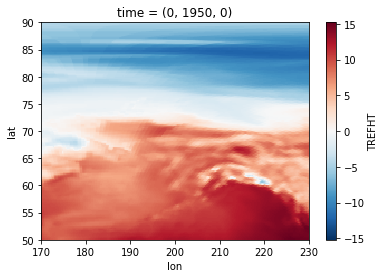

In [19]:
ds_all_times.isel(time=0).plot()

In [20]:
# calculate mean over all autumn to get anomalies

# Calculate seasonal mean
mean = ds_all_times.mean(dim=['time'])

# get spatial anomalies each day
ds_all_times_anom = ds_all_times - mean

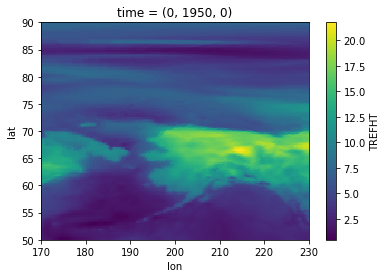

In [21]:
ds_all_times_anom.isel(time=0).plot()

## Make node composite averages
- Both over all time and for decades (1950, 2000, 2050, 2090)

In [22]:
data = ds_all_times_anom

In [23]:
# choose decades we'll look at
# these will become coordinate arrays
decades = list(range(1950,2100,10))
decade_names = ['1950','1960','1970','1980','1990','2000','2010','2020','2030','2040','2050','2060','2070','2080','2090']

months = list(range(9,13,1))
month_names = ['9','10','11','12']

nodes = list(range(0,len(som_keys),1))
nnodes = len(nodes)

In [24]:
# get all training times
all_times = subset.training_times
all_yy = all_times.decades
# all days - this is the DOY from Sept.1 to Dec.31 (122) for all three years (3x122 = 366)
# all_dd = all_times.autumn_days

In [25]:
# make numpy arrays to fill with frequencies
node_all = np.zeros([nnodes,len(data.lat),len(data.lon)])

# loop through the different maps to get the indices of training data that map there
for map_num in range(len(som_keys)):
#for map_num in range(len(som_keys))[0:1]:
    # get indices of training data that mapped to this node
    inds = winmap[som_keys[map_num]]
    print(len(inds))
    # grab the compositing data that corresponds to those training times
    with dask.config.set(**{'array.slicing.split_large_chunks': False}):
        ds_sub = data.isel(time=inds)      
    # grab data for the subset of years and average
    node_all[map_num,:,:] = ds_sub.mean(dim="time", skipna=True).data

6064
5139
4252
7144
6622
6083
3896
5552
4658


In [26]:
print(node_all.shape)

(9, 160, 240)


In [27]:
# convert the numpy array to a xarray and set coordinate arrays
node_composite_all = xr.DataArray(node_all,dims=('node','lat','lon'))
node_composite_all['node'] = nodes
node_composite_all['lat'] = data.lat
node_composite_all['lon'] = data.lon

## Make Plots

In [28]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'

In [29]:
## set colors
cmap_choice = plt.cm.get_cmap('coolwarm')

# set lat/lon bounds
lat_max = 72
lat_min = 52
lon_max = 218
lon_min = 182
lon_avg = 200

# set plotting info
units = '$^o$C'
vmin_in = -10
vmax_in = 10 
ticks_1 = np.arange(vmin_in,vmax_in+5,5)

In [30]:
# set node names
node_names = ['0a', '0b', '0c', '1a', '1b', '1c', '2a', '2b', '2c']

### Plot anomaly composite maps over all time

node: 0


/glade/work/duvivier/miniconda3/envs/antarctica_som_env/lib/python3.7/site-packages/cartopy/mpl/geoaxes.py:1763: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  result = matplotlib.axes.Axes.pcolor(self, *args, **kwargs)


node: 1
node: 2
node: 3
node: 4
node: 5
node: 6
node: 7
node: 8


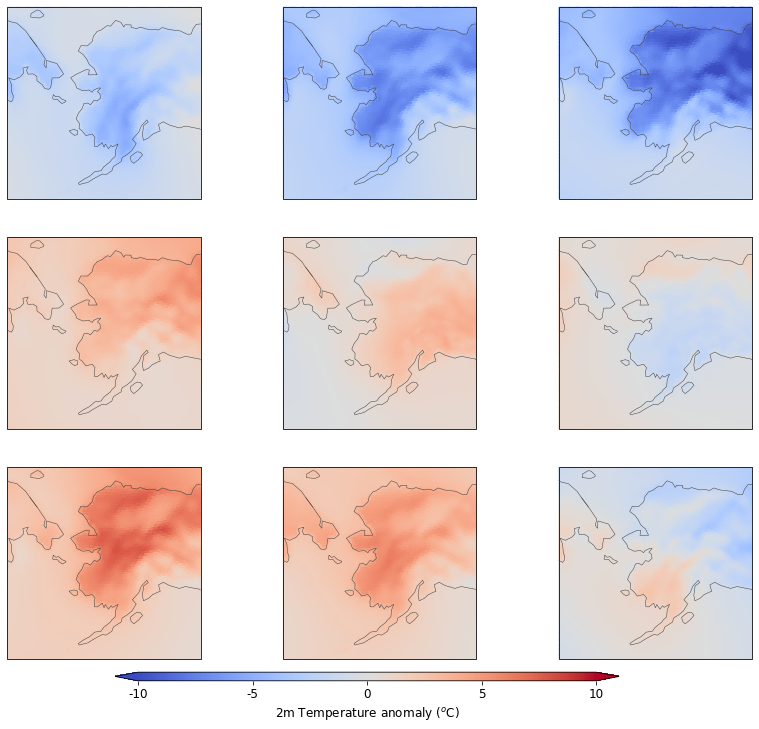

In [31]:
# set some of the plot info
fig, axs = plt.subplots(som_row, som_col, subplot_kw={'projection':ccrs.Stereographic(central_longitude=lon_avg)}, figsize=(14,12))

# set info for this plot
ds_plot = node_composite_all
file_out = 'supp_fig_som_2mT_anomaly_composite_all_times.png'

# loop through the different maps to get the indices of training data that map there
for map_num in range(len(som_keys)):
    print('node: '+str(map_num))
    # grab the composite data that corresponds to those training times and node
    ds_sub = ds_plot.isel(node=map_num)

    # make plot for this node - note using .values converts from xarray to numpy array
    cs = axs[som_keys[map_num][0],som_keys[map_num][1]].pcolor(ds_sub.coords['lon'].values, 
                                                               ds_sub.coords['lat'].values, 
                                                               ds_sub.values, 
                                                               vmin=vmin_in, vmax=vmax_in, cmap=cmap_choice,
                                                               transform=ccrs.PlateCarree())
    # modify the plots
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_extent([lon_min,lon_max,lat_min,lat_max])
    axs[som_keys[map_num][0],som_keys[map_num][1]].coastlines(resolution='110m', color='0.25', linewidth=0.5, zorder=10)    

# colorbar stuff
cbar_ax = fig.add_axes([0.25,0.1,0.5,0.01]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_1[:], orientation='horizontal', extend='both')
cbar.ax.set_xticklabels(list(ticks_1))
cbar.ax.tick_params(labelsize=12)
cbar.set_label('2m Temperature anomaly ('+units+')', fontsize=12)
    
# save figure
plt.savefig(file_out, bbox_inches='tight', dpi=200)
plt.savefig(dir_out+file_out, bbox_inches='tight', dpi=200)

### Plot Just pattern 2a

In [32]:
# set lat/lon bounds
lat_max = 72
lat_min = 52
lon_max = 208
lon_min = 192
lon_avg = 200

figure_5_2mT_anomaly_pattern_2a.png


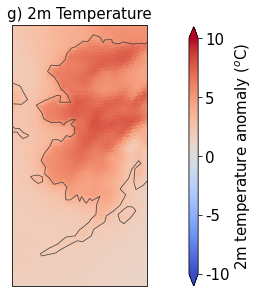

In [33]:
# set some of the plot info

# set info for this plot - just pattern 2a!
ds_plot = node_composite_all.sel(node=6)
file_out = 'figure_5_2mT_anomaly_pattern_2a.png'
print(file_out)

# make plot
#fig = plt.figure(figsize=(10,10))
fig = plt.figure(figsize=(6.4,4.8))
ax = fig.add_subplot(1,1,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
cs = ax.pcolormesh(ds_plot.coords['lon'].values,ds_plot.coords['lat'].values,ds_plot.values,
                   vmin=vmin_in, vmax=vmax_in, cmap=cmap_choice, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m', color='0.25', linewidth=0.75, zorder=10)
plt.title('g) 2m Temperature',fontsize=15)

# colorbar stuff
cbar_ax = fig.add_axes([0.75,0.125,0.02,0.75]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_1[:],orientation='vertical', extend='both')
cbar.ax.set_yticklabels(list(ticks_1))
cbar.ax.tick_params(labelsize=15)
cbar.set_label('2m temperature anomaly ('+units+')', fontsize=15)
    
# save figure
plt.savefig(file_out, bbox_inches='tight', dpi=200)
plt.savefig(dir_out+file_out, bbox_inches='tight', dpi=200)